In [3]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 


Matplotlib is building the font cache; this may take a moment.


In [5]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width",150)
sns.set_style("whitegrid")

df = pd.read_csv("Insurance claims data.csv")

In [8]:
df.head()
df.columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 58592 entries, 0 to 58591
Data columns (total 41 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   policy_id                         58592 non-null  str    
 1   subscription_length               58592 non-null  float64
 2   vehicle_age                       58592 non-null  float64
 3   customer_age                      58592 non-null  int64  
 4   region_code                       58592 non-null  str    
 5   region_density                    58592 non-null  int64  
 6   segment                           58592 non-null  str    
 7   model                             58592 non-null  str    
 8   fuel_type                         58592 non-null  str    
 9   max_torque                        58592 non-null  str    
 10  max_power                         58592 non-null  str    
 11  engine_type                       58592 non-null  str    
 12  airbags        

In [ ]:
df["claim_status"].value_counts() # ilosc zgloszen rozszczeń 

claim_status
0    54844
1     3748
Name: count, dtype: int64

In [ ]:
df.isna().sum() # czy jest jakas kolumna z pustymi wartosciami


policy_id                           0
subscription_length                 0
vehicle_age                         0
customer_age                        0
region_code                         0
region_density                      0
segment                             0
model                               0
fuel_type                           0
max_torque                          0
max_power                           0
engine_type                         0
airbags                             0
is_esc                              0
is_adjustable_steering              0
is_tpms                             0
is_parking_sensors                  0
is_parking_camera                   0
rear_brakes_type                    0
displacement                        0
cylinder                            0
transmission_type                   0
steering_type                       0
turning_radius                      0
length                              0
width                               0
gross_weight

In [ ]:
df.duplicated().sum() # czy sa zduplikowane jakies wiersze?

np.int64(0)

In [ ]:
df["claim_status"].value_counts(normalize=True)* 100 # normalizacja wartosci ilosci grup statusu zgloszen


claim_status
0    93.603222
1     6.396778
Name: proportion, dtype: float64

In [ ]:
num_cols = df.select_dtypes(include = ["int64", "float64"]).columns.to_list() #lista kolumn typu liczbowego
num_cols

['subscription_length',
 'vehicle_age',
 'customer_age',
 'region_density',
 'airbags',
 'displacement',
 'cylinder',
 'turning_radius',
 'length',
 'width',
 'gross_weight',
 'ncap_rating',
 'claim_status']

In [19]:
obj_columns = df.select_dtypes(include=["object","str"]).columns.to_list()

In [21]:
len(obj_columns)

28

In [22]:
num_cols.remove("claim_status") #usuniecie tylko kolumny do predykcji czyli statusu zgloszen do polisy
obj_columns.remove("policy_id") # usuniecie id polisy - nieistotna 

In [24]:
for col in obj_columns:
    uniques = df[col].unique()
    print(f"{col:35s} - unique values {df[col].nunique():3d} - sample {uniques[:5]}")

region_code                         - unique values  22 - sample <StringArray>
['C8', 'C2', 'C10', 'C13', 'C7']
Length: 5, dtype: str
segment                             - unique values   6 - sample <StringArray>
['C2', 'C1', 'A', 'B2', 'B1']
Length: 5, dtype: str
model                               - unique values  11 - sample <StringArray>
['M4', 'M9', 'M1', 'M5', 'M7']
Length: 5, dtype: str
fuel_type                           - unique values   3 - sample <StringArray>
['Diesel', 'CNG', 'Petrol']
Length: 3, dtype: str
max_torque                          - unique values   9 - sample <StringArray>
['250Nm@2750rpm', '200Nm@1750rpm', '60Nm@3500rpm', '200Nm@3000rpm', '113Nm@4400rpm']
Length: 5, dtype: str
max_power                           - unique values   9 - sample <StringArray>
['113.45bhp@4000rpm', '97.89bhp@3600rpm', '40.36bhp@6000rpm', '88.77bhp@4000rpm', '88.50bhp@6000rpm']
Length: 5, dtype: str
engine_type                         - unique values  11 - sample <StringArray>
['1.5 

In [27]:
binary_cols = [ c for c in obj_columns if set(df[c].unique()) <= {"Yes","No"}]

In [28]:
binary_cols


['is_esc',
 'is_adjustable_steering',
 'is_tpms',
 'is_parking_sensors',
 'is_parking_camera',
 'is_front_fog_lights',
 'is_rear_window_wiper',
 'is_rear_window_washer',
 'is_rear_window_defogger',
 'is_brake_assist',
 'is_power_door_locks',
 'is_central_locking',
 'is_power_steering',
 'is_driver_seat_height_adjustable',
 'is_day_night_rear_view_mirror',
 'is_ecw',
 'is_speed_alert']

In [ ]:
result = []
for col in binary_cols:
    rates = df.groupby(col)["claim_status"].mean() * 100 # grupuje dane wg unikalnych warosci yes/no i liczy srednia dla kolumny claim status - czyli jako wskaznik wystapienia roszczenia
    gap = abs(rates.get("Yes", 0 ) - rates.get("No",0)) # obliczenie roznicy - pobiera obliczony procent dla kategorii Yes i No i oblicza bezwzgledna roznize miedzy nimi
    result.append((col, rates.get("No", np.nan), rates.get("Yes", np.nan), gap)) # dodaje krotke kolumna, odsetek no, odsetek yes i roznica


In [ ]:
result


[('is_esc',
  np.float64(6.347192157448185),
  np.float64(6.5050812455844795),
  np.float64(0.15788908813629465)),
 ('is_adjustable_steering',
  np.float64(5.97416110292205),
  np.float64(6.671170410403649),
  np.float64(0.6970093074815988)),
 ('is_tpms',
  np.float64(6.38713151164356),
  np.float64(6.42745042088743),
  np.float64(0.04031890924387049)),
 ('is_parking_sensors',
  np.float64(5.39401601348504),
  np.float64(6.439104217435386),
  np.float64(1.0450882039503453)),
 ('is_parking_camera',
  np.float64(6.413847187990142),
  np.float64(6.370150297098917),
  np.float64(0.043696890891225415)),
 ('is_front_fog_lights',
  np.float64(6.057411612066169),
  np.float64(6.643480311247347),
  np.float64(0.5860686991811779)),
 ('is_rear_window_wiper',
  np.float64(6.355382619974059),
  np.float64(6.49840783111216),
  np.float64(0.14302521113810052)),
 ('is_rear_window_washer',
  np.float64(6.355382619974059),
  np.float64(6.49840783111216),
  np.float64(0.14302521113810052)),
 ('is_rear_wi

In [36]:
gap_df = pd.DataFrame(result, columns= ["feauture", "claim_rate_No", "claim_rate_Yes", "gap"]).sort_values("gap", ascending = False)

len(result)

17

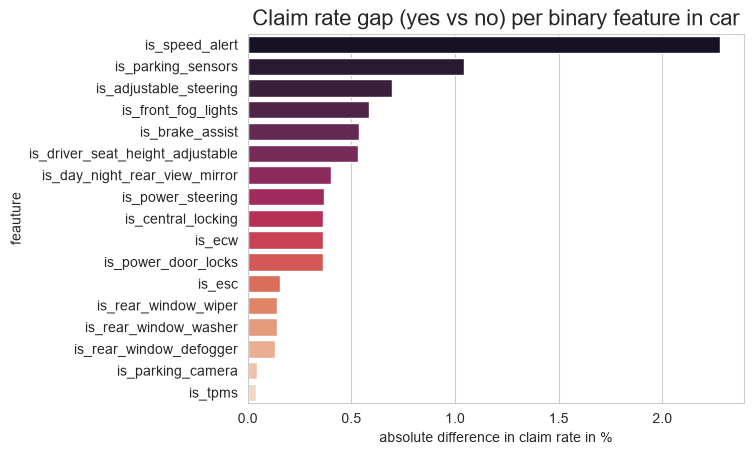

In [47]:
sns.barplot(data = gap_df , y = "feauture", x ="gap", palette="rocket" , hue ="feauture"  )
plt.title("Claim rate gap (yes vs no) per binary feature in car", fontsize = 16)
plt.xlabel("absolute difference in claim rate in %")
plt.show()



In [48]:
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
subscription_length,58592.0,6.111688,4.142790,0.0,2.1,5.7,10.4,14.0
vehicle_age,58592.0,1.388473,1.134413,0.0,0.4,1.2,2.2,20.0
customer_age,58592.0,44.823935,6.935604,35.0,39.0,44.0,49.0,75.0
region_density,58592.0,18826.858667,17660.174792,290.0,6112.0,8794.0,27003.0,73430.0
airbags,58592.0,3.137066,1.832641,1.0,2.0,2.0,6.0,6.0
displacement,58592.0,1162.355851,266.304786,796.0,796.0,1197.0,1493.0,1498.0
cylinder,58592.0,3.626963,0.483616,3.0,3.0,4.0,4.0,4.0
turning_radius,58592.0,4.852893,0.228061,4.5,4.6,4.8,5.0,5.2
length,58592.0,3850.476891,311.457119,3445.0,3445.0,3845.0,3995.0,4300.0
width,58592.0,1672.233667,112.089135,1475.0,1515.0,1735.0,1755.0,1811.0


In [49]:
df.groupby("claim_status")[num_cols].mean().T.round(2)

claim_status,0,1
subscription_length,6.03,7.36
vehicle_age,1.40,1.27
customer_age,44.78,45.41
region_density,18909.07,17623.82
airbags,3.14,3.16
displacement,1161.82,1170.18
cylinder,3.63,3.65
turning_radius,4.85,4.86
length,3849.95,3858.21
width,1671.94,1676.50


In [54]:
cat_to_explore= ["region_code","model", "segment","fuel_type", "transmission_type", "steering_type"]
for col in cat_to_explore:
    grp  = df.groupby(col)["claim_status"].agg(["count", "mean"]).sort_values("count", ascending = False)
    grp["mean"] = (grp["mean"] * 100 ).round(2)
    print(f"- {col} -")
    print(grp.head(10))

grp


- region_code -
             count  mean
region_code             
C8           13654  6.99
C2            7342  7.08
C5            6979  5.77
C3            6101  7.10
C14           3660  7.68
C13           3423  5.70
C10           3155  4.69
C9            2734  4.97
C7            2167  5.03
C12           1589  5.48
- model -
       count  mean
model             
M1     14948  6.14
M4     14018  6.43
M6     13776  6.82
M8      4173  5.85
M7      2940  6.84
M3      2373  5.39
M9      2114  6.29
M5      1598  7.26
M10     1209  6.04
M2      1080  7.41
- segment -
         count  mean
segment             
B2       18314  6.86
A        17321  6.04
C2       14018  6.43
B1        4173  5.85
C1        3557  6.41
Utility   1209  6.04
- fuel_type -
           count  mean
fuel_type             
Petrol     20532  6.64
CNG        20330  6.07
Diesel     17730  6.49
- transmission_type -
                   count  mean
transmission_type             
Manual             38181  6.39
Automatic          204

,count,mean
steering_type,,
Power,33502,6.20
Electric,23881,6.69
Manual,1209,6.04


C:\Users\misia\AppData\Local\Temp\ipykernel_14816\545417691.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = grp.values, y = grp.index , ax = ax, palette ="mako")
C:\Users\misia\AppData\Local\Temp\ipykernel_14816\545417691.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = grp.values, y = grp.index , ax = ax, palette ="mako")
C:\Users\misia\AppData\Local\Temp\ipykernel_14816\545417691.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = grp.values, y = grp.index , ax = ax, palette ="mako")
C:\Users\misia\AppData\Local\Temp\ipy

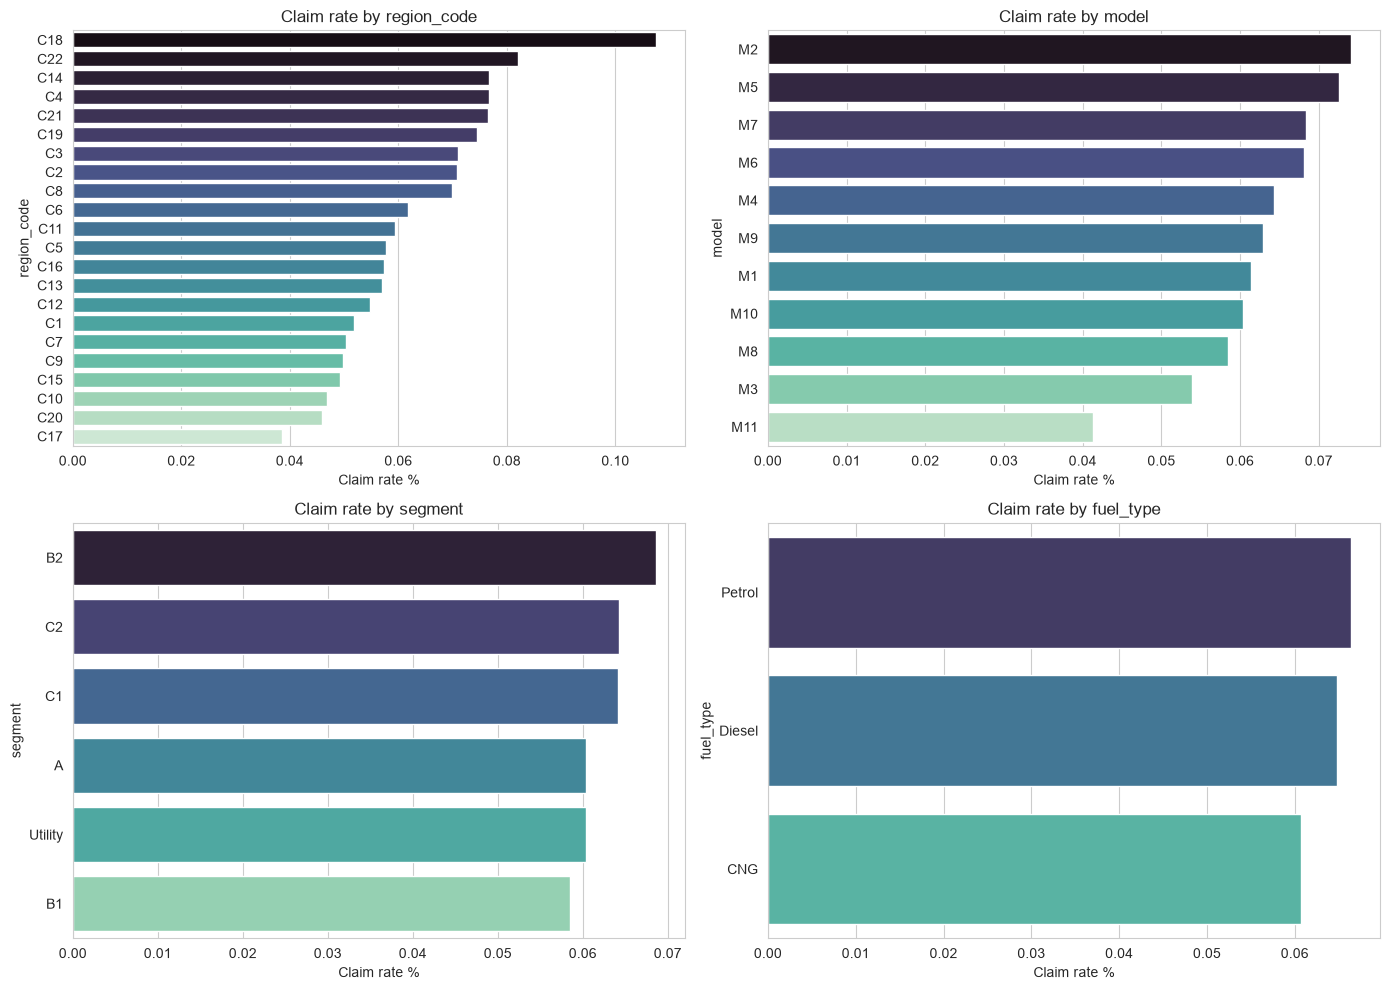

In [55]:
fig, axes = plt.subplots(2,2, figsize = (14,10))
for ax, col in zip(axes.flat , ["region_code", "model", "segment", "fuel_type"]):
    grp = df.groupby(col)["claim_status"].mean().sort_values(ascending =False)
    sns.barplot(x = grp.values, y = grp.index , ax = ax, palette ="mako")
    ax.set_title(f"Claim rate by {col}")
    ax.set_xlabel("Claim rate %")

plt.tight_layout()
plt.show()


In [56]:
corr_cols = num_cols + ["claim_status"]
corr = df[corr_cols].corr()


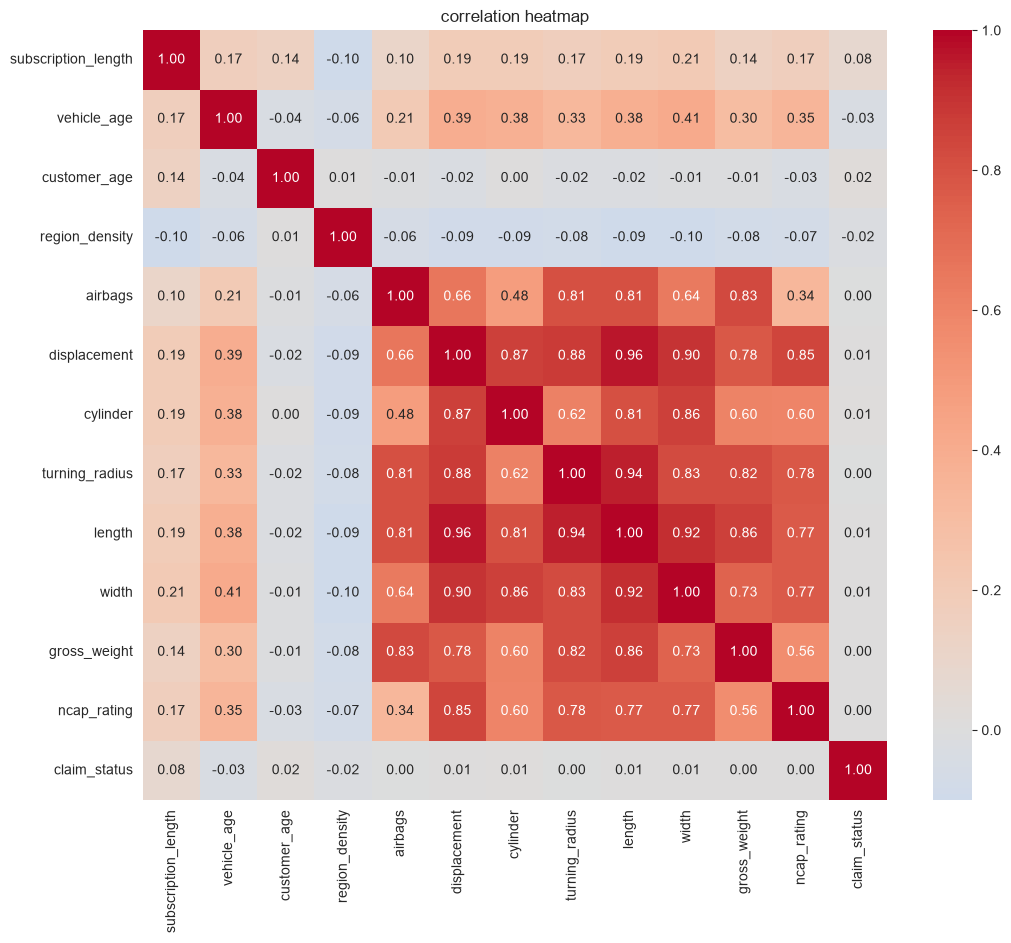

In [57]:
plt.figure(figsize=(12,10))
sns.heatmap(corr, annot = True, fmt = ".2f" , cmap = "coolwarm", center =0 )
plt.title("correlation heatmap")
plt.show()

In [60]:
for col in ["subscription_length", "vehicle_age", "customer_age"]:
    print(f"---- {col} ---- ")
    print(df[col].describe(percentiles = [0.01, .05, .25, .5,.75, .95,.99]))

---- subscription_length ---- 
count    58592.000000
mean         6.111688
std          4.142790
min          0.000000
1%           0.100000
5%           0.400000
25%          2.100000
50%          5.700000
75%         10.400000
95%         12.000000
99%         12.400000
max         14.000000
Name: subscription_length, dtype: float64
---- vehicle_age ---- 
count    58592.000000
mean         1.388473
std          1.134413
min          0.000000
1%           0.000000
5%           0.000000
25%          0.400000
50%          1.200000
75%          2.200000
95%          3.400000
99%          4.200000
max         20.000000
Name: vehicle_age, dtype: float64
---- customer_age ---- 
count    58592.000000
mean        44.823935
std          6.935604
min         35.000000
1%          35.000000
5%          35.000000
25%         39.000000
50%         44.000000
75%         49.000000
95%         58.000000
99%         63.000000
max         75.000000
Name: customer_age, dtype: float64
